In [432]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from numpy import mean
from numpy import absolute
from numpy import sqrt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import RFE
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn import metrics
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

In [433]:
bowlingStats=pd.read_csv("bowlingSalaries.csv")
bowlingStatsCopy=bowlingStats.copy()
bowlingStats=bowlingStats[(bowlingStats['O'] > 8.0) & (bowlingStats['I']>3) & (bowlingStats['W']>8)]
bowlingStats['Salary']=bowlingStats['Salary'].apply(lambda x:int(x.replace(',', '')))
bowlingStatsOrig=bowlingStats.copy()
bowlingStats = bowlingStats.drop(columns=['Year','BBI','Player'])
bowlingStats

,I,O,R,W,Econ,Avg,SR,4W,5W,4s,6s,Dots,Salary
1,8,30.2,187,12,6.16,15.58,15.17,0,0,17,2,84,28600
4,8,19.0,188,11,9.89,17.09,10.36,0,1,18,8,39,1328130
7,12,46.0,306,15,6.65,20.40,18.40,0,0,16,13,99,714300
8,12,41.2,342,18,8.27,19.00,13.78,0,1,27,11,88,28600
9,16,61.0,450,24,7.38,18.75,15.25,0,0,41,15,156,109380
...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,13,46.4,431,16,9.24,26.94,17.50,0,0,33,24,113,406250
376,16,61.0,467,17,7.66,27.47,21.53,0,0,36,20,137,1953130
379,14,52.4,466,18,8.85,25.89,17.56,0,0,46,18,118,343750
381,14,53.1,418,20,7.86,20.90,15.95,0,0,40,19,149,656250


Index(['I', 'O', 'R', 'W', 'Econ', 'Avg', 'SR', '4W', '5W', '4s', '6s', 'Dots',
       'Salary'],
      dtype='object')

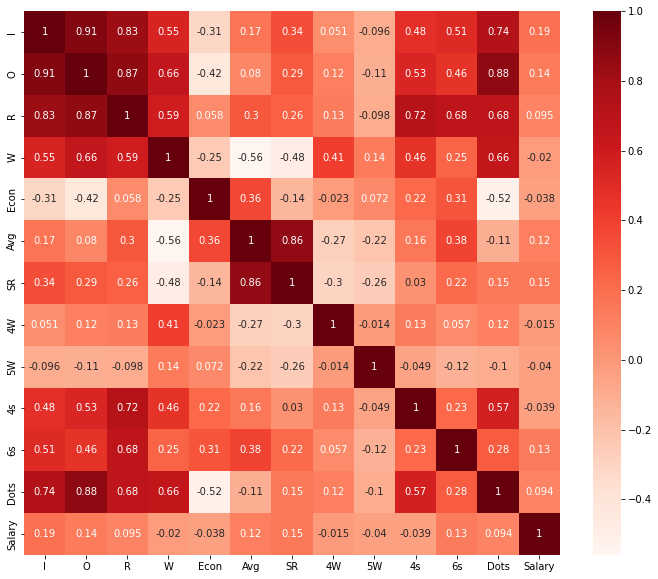

In [446]:
correlationDf=bowlingStats.copy()
plt.figure(figsize=(12,10))
cor = correlationDf.corr()
sns.heatmap(cor, annot=True, cmap=plt.cm.Reds)
plt.show
correlationDf.columns

In [449]:
import statsmodels.api as sm
X=bowlingStats[['I', 'O', 'R', 'W', 'Econ', 'Avg', 'SR', '4W', '5W', '4s', '6s', 'Dots']]
y=bowlingStats[['Salary']]
cols = list(X.columns)
pmax = 1
while (len(cols)>0):
    p= []
    X_1 = X[cols]
    X_1 = sm.add_constant(X_1)
    model = sm.OLS(y,X_1).fit()
    p = pd.Series(model.pvalues.values[1:],index = cols)      
    pmax = max(p)
    feature_with_p_max = p.idxmax()
    if(pmax>0.05):
        cols.remove(feature_with_p_max)
    else:
        break
selected_features_BE = cols
print(selected_features_BE)

['I']


In [415]:
sc_x = StandardScaler()
sc_y = StandardScaler()
X = sc_x.fit_transform(bowlingStats.iloc[:,1:-1])
y = sc_y.fit_transform(bowlingStats.iloc[:,-1:])
lr=LinearRegression()
lr.fit(X,y)
predictions=sc_y.inverse_transform(lr.predict(X))
predictions=predictions.reshape(predictions.shape[0],)
mse_regression= mean_squared_error(bowlingStatsOrig.Salary, predictions)
predictedSalaries = pd.DataFrame({'Player':bowlingStatsOrig['Player'],'ActualSalary':bowlingStatsOrig['Salary'] ,'LinearRegressionSalaries': predictions})
predictedSalaries['ActualSalary'] = predictedSalaries['ActualSalary'].astype(int)
predictedSalaries['LinearRegressionSalaries'] = predictedSalaries['LinearRegressionSalaries'].astype(int)
predictedSalaries

,Player,ActualSalary,LinearRegressionSalaries
1,A Nortje,28600,272735
4,AD Russell,1328130,803302
7,AR Patel,714300,758312
8,Arshdeep Singh,28600,532808
9,Avesh Khan,109380,712222
...,...,...,...
375,SN Thakur,406250,700160
376,SP Narine,1953130,939506
379,TA Boult,343750,573359
381,UT Yadav,656250,665687


In [416]:
svr_regressor = SVR(kernel = 'rbf')
svr_regressor.fit(X, y)
predictions=sc_y.inverse_transform(svr_regressor.predict(X))
predictions=predictions.reshape(predictions.shape[0],)
mse_SVR= mean_squared_error(bowlingStatsOrig.Salary, predictions)
predictedSalaries['SVR_Regression_Salaries']=predictions
predictedSalaries['SVR_Regression_Salaries']=predictedSalaries['SVR_Regression_Salaries'].astype(int)
predictedSalaries

c:\users\rajee\appdata\local\programs\python\python38\lib\site-packages\sklearn\utils\validation.py:63: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return f(*args, **kwargs)


,Player,ActualSalary,LinearRegressionSalaries,SVR_Regression_Salaries
1,A Nortje,28600,272735,90428
4,AD Russell,1328130,803302,900209
7,AR Patel,714300,758312,766195
8,Arshdeep Singh,28600,532808,361267
9,Avesh Khan,109380,712222,747406
...,...,...,...,...
375,SN Thakur,406250,700160,691272
376,SP Narine,1953130,939506,722721
379,TA Boult,343750,573359,599038
381,UT Yadav,656250,665687,678434


In [417]:
regression_tree = DecisionTreeRegressor(max_depth=4,random_state=10)
regression_tree.fit(X,y)
predictions=sc_y.inverse_transform(regression_tree.predict(X))
predictions=predictions.reshape(predictions.shape[0],)
mse_reg_tree=mean_squared_error(bowlingStatsOrig.Salary,predictions)
predictedSalaries['RegressionTreeSalaries']=predictions
predictedSalaries['RegressionTreeSalaries']=predictedSalaries['RegressionTreeSalaries'].astype("int")
predictedSalaries

,Player,ActualSalary,LinearRegressionSalaries,SVR_Regression_Salaries,RegressionTreeSalaries
1,A Nortje,28600,272735,90428,79642
4,AD Russell,1328130,803302,900209,1328130
7,AR Patel,714300,758312,766195,856984
8,Arshdeep Singh,28600,532808,361267,406393
9,Avesh Khan,109380,712222,747406,856984
...,...,...,...,...,...
375,SN Thakur,406250,700160,691272,955777
376,SP Narine,1953130,939506,722721,856984
379,TA Boult,343750,573359,599038,406393
381,UT Yadav,656250,665687,678434,856984


In [418]:
neighbors = np.arange(1, 100, 2)
scores = []
for k in neighbors:   # running for different K values to know which yields the max accuracy. 
    clf = KNeighborsRegressor(n_neighbors = k,  weights = 'distance', p=1)
    clf.fit(x, y)
    score = cross_val_score(clf, x, y, cv = 10)
    scores.append(score.mean())
mse = [1-x for x in scores]
optimal_k = neighbors[mse.index(min(mse))]
print("Optimal K: ", optimal_k)

Optimal K:  43


In [419]:
knn_regression = KNeighborsRegressor(n_neighbors = optimal_k)
knn_regression.fit(x, y)
predictions= sc_y.inverse_transform(knn_regression.predict(x))
predictedSalaries['KNNPredictions']=predictions
predictedSalaries['KNNPredictions']=predictedSalaries['KNNPredictions'].astype(int)
predictedSalaries.head(50)

,Player,ActualSalary,LinearRegressionSalaries,SVR_Regression_Salaries,RegressionTreeSalaries,KNNPredictions
1,A Nortje,28600,272735,90428,79642,637215
4,AD Russell,1328130,803302,900209,1328130,615270
7,AR Patel,714300,758312,766195,856984,740347
8,Arshdeep Singh,28600,532808,361267,406393,718297
9,Avesh Khan,109380,712222,747406,856984,763256
12,C Sakariya,171400,735189,537692,406393,731771
13,CH Morris,2321400,704563,773578,2020075,724460
16,CV Varun,1200000,1233189,1258049,856984,811942
17,DJ Bravo,1000000,529989,357528,856984,638098
19,DL Chahar,125000,817271,318302,406393,695884


In [423]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators = 100, random_state = 0)
regressor.fit(x, y)
predictions=sc_y.inverse_transform(regressor.predict(x))
predictedSalaries['RandomForestRegressor']=predictions
predictedSalaries

C:\Users\rajee\AppData\Local\Temp/ipykernel_3784/3554245608.py:3: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  regressor.fit(x, y)


,Player,ActualSalary,LinearRegressionSalaries,SVR_Regression_Salaries,RegressionTreeSalaries,KNNPredictions,RandomForestRegressor
1,A Nortje,28600,272735,90428,79642,637215,216553.4
4,AD Russell,1328130,803302,900209,1328130,615270,909032.7
7,AR Patel,714300,758312,766195,856984,740347,754992.2
8,Arshdeep Singh,28600,532808,361267,406393,718297,363393.5
9,Avesh Khan,109380,712222,747406,856984,763256,391880.1
...,...,...,...,...,...,...,...
375,SN Thakur,406250,700160,691272,955777,657685,688623.1
376,SP Narine,1953130,939506,722721,856984,833663,1377229.6
379,TA Boult,343750,573359,599038,406393,741115,543240.6
381,UT Yadav,656250,665687,678434,856984,772169,739693.8
